
# Wine Quality Prediction

## OIBSIP Data Analytics Internship — Level 2, Task 2

### Project Overview
This project analyzes the physicochemical properties of red wine and builds machine learning models to predict wine quality.

### Objectives
- Load and inspect the dataset.
- Clean and validate the data.
- Perform exploratory data analysis (EDA).
- Identify relationships between chemical properties and quality.
- Train and compare regression models.
- Evaluate predictions using appropriate metrics.
- Visualize results and summarize findings.

### Dataset
Source: UCI Machine Learning Repository — Wine Quality Dataset.

The dataset contains red wine samples, 11 physicochemical input features, and a quality score.

### Tools
Python, Pandas, NumPy, Matplotlib, Seaborn, and Scikit-learn.


In [1]:

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Consistent visualization settings
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

# Project paths
PROJECT_DIR = Path.cwd().parent
DATA_PATH = PROJECT_DIR / "data" / "winequality-red.csv"
IMAGES_DIR = PROJECT_DIR / "images"

IMAGES_DIR.mkdir(parents=True, exist_ok=True)

print("Project folder:", PROJECT_DIR)
print("Dataset path:", DATA_PATH)
print("Images folder:", IMAGES_DIR)


Project folder: c:\Users\Lamis\Desktop\OIBSIP\DataAnalytics-L2-WineQualityPrediction
Dataset path: c:\Users\Lamis\Desktop\OIBSIP\DataAnalytics-L2-WineQualityPrediction\data\winequality-red.csv
Images folder: c:\Users\Lamis\Desktop\OIBSIP\DataAnalytics-L2-WineQualityPrediction\images


In [2]:

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found at: {DATA_PATH}\n"
        "Make sure winequality-red.csv is inside the project's data folder."
    )

df = pd.read_csv(DATA_PATH, sep=";")

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

display(df.head())


Dataset loaded successfully!
Number of rows: 1599
Number of columns: 12


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [3]:

print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types and non-null counts:")
df.info()

print("\nStatistical summary:")
display(df.describe().round(2))


Dataset shape: (1599, 12)

Column names:
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']

Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.00,1599.00,1599.00,1599.00,1599.00,1599.00,1599.00,1599.00,1599.00,1599.00,1599.00,1599.00
mean,8.32,0.53,0.27,2.54,0.09,15.87,46.47,1.00,3.31,0.66,10.42,5.64
std,1.74,0.18,0.19,1.41,0.05,10.46,32.90,0.00,0.15,0.17,1.07,0.81
min,4.60,0.12,0.00,0.90,0.01,1.00,6.00,0.99,2.74,0.33,8.40,3.00
25%,7.10,0.39,0.09,1.90,0.07,7.00,22.00,1.00,3.21,0.55,9.50,5.00
50%,7.90,0.52,0.26,2.20,0.08,14.00,38.00,1.00,3.31,0.62,10.20,6.00
75%,9.20,0.64,0.42,2.60,0.09,21.00,62.00,1.00,3.40,0.73,11.10,6.00
max,15.90,1.58,1.00,15.50,0.61,72.00,289.00,1.00,4.01,2.00,14.90,8.00


In [4]:

print("Missing values per column:")
display(df.isnull().sum())

print("Number of duplicated rows:", df.duplicated().sum())

print("\nQuality score distribution:")
display(df["quality"].value_counts().sort_index())

print("\nRows with non-positive quality scores:")
print((df["quality"] <= 0).sum())

print("\nRows with non-numeric or infinite values:")
numeric_values = df.select_dtypes(include=np.number)
print(np.isinf(numeric_values).sum().sum())


Missing values per column:


fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

Number of duplicated rows: 240

Quality score distribution:


quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64


Rows with non-positive quality scores:
0

Rows with non-numeric or infinite values:
0


In [5]:

original_rows = len(df)

df = df.drop_duplicates().copy()
df = df.dropna(subset=["quality"]).copy()

numeric_columns = df.select_dtypes(include=np.number).columns
df = df.replace([np.inf, -np.inf], np.nan)

# Quality is the value we want to predict, so it must be present.
df = df.dropna(subset=["quality"])

print("Rows before cleaning:", original_rows)
print("Rows after removing duplicates and missing targets:", len(df))
print("Rows removed:", original_rows - len(df))
print("Remaining missing values:")
display(df.isnull().sum())


Rows before cleaning: 1599
Rows after removing duplicates and missing targets: 1359
Rows removed: 240
Remaining missing values:


fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

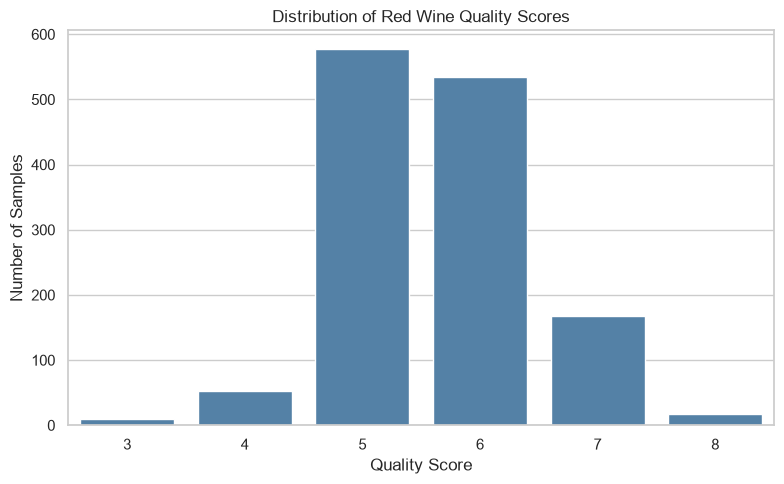

In [6]:

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="quality", color="steelblue")

plt.title("Distribution of Red Wine Quality Scores")
plt.xlabel("Quality Score")
plt.ylabel("Number of Samples")
plt.tight_layout()

plt.savefig(IMAGES_DIR / "quality_distribution.png", dpi=300, bbox_inches="tight")
plt.show()


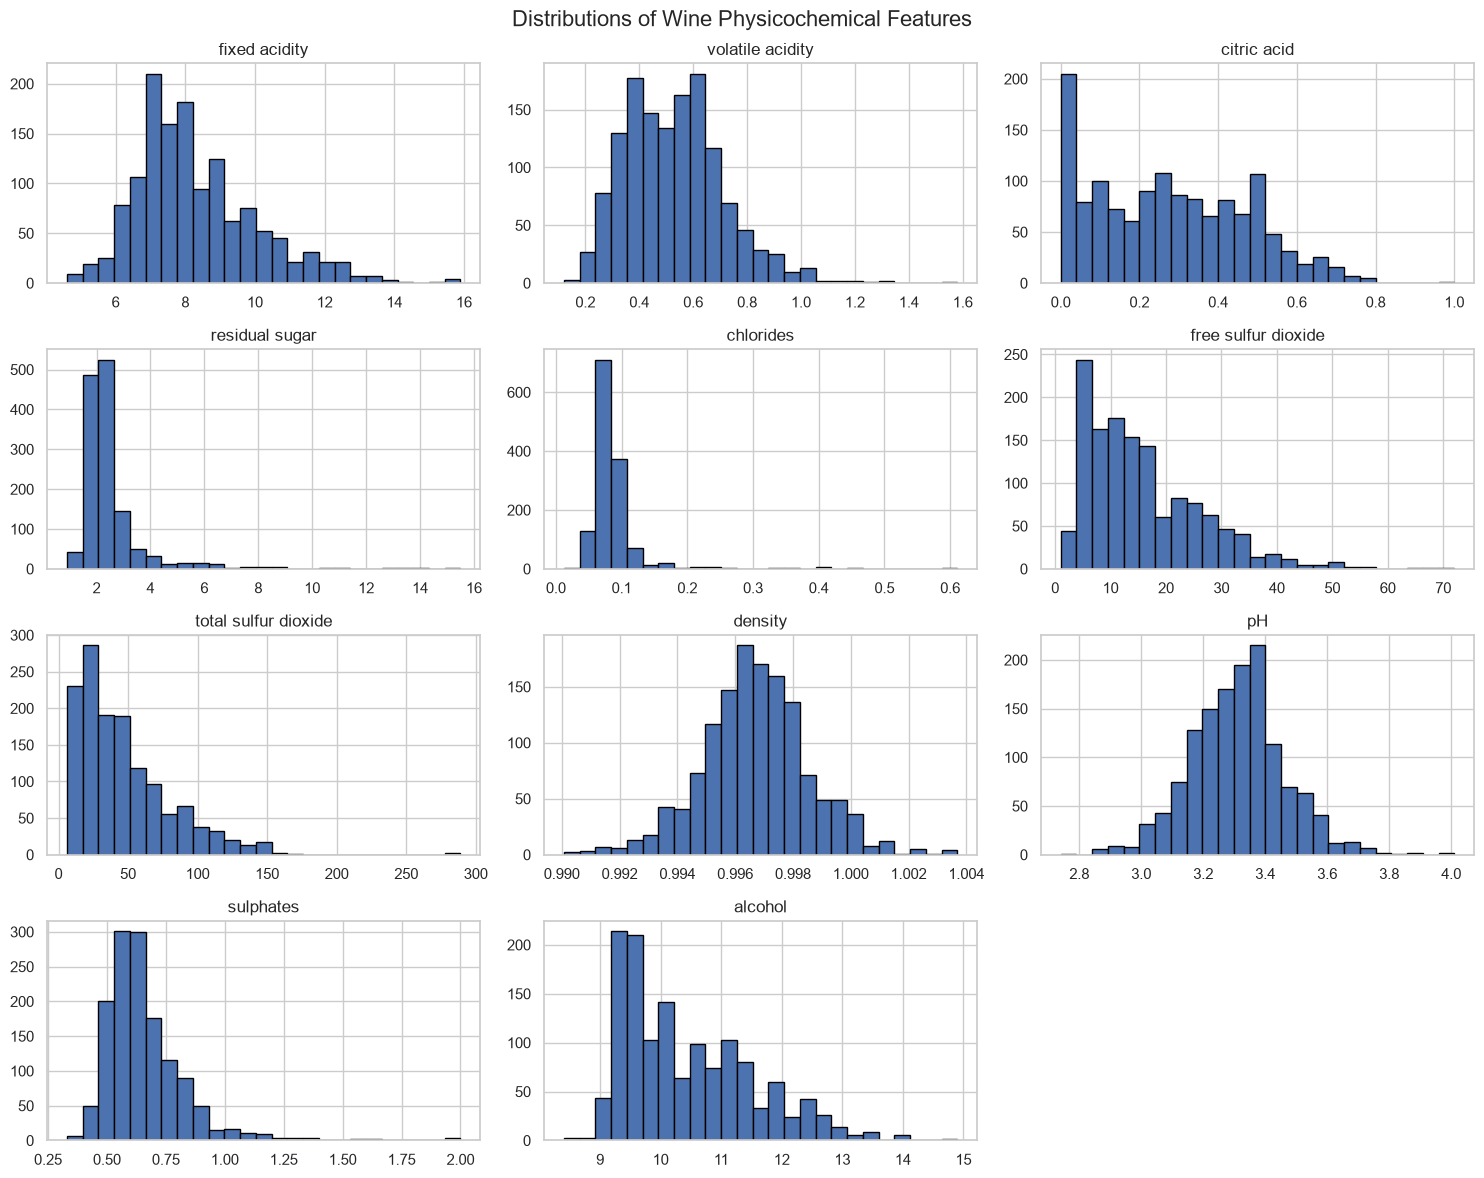

In [7]:

df.drop(columns=["quality"]).hist(
    figsize=(15, 12),
    bins=25,
    edgecolor="black"
)

plt.suptitle("Distributions of Wine Physicochemical Features", fontsize=16)
plt.tight_layout()

plt.savefig(IMAGES_DIR / "feature_distributions.png", dpi=300, bbox_inches="tight")
plt.show()


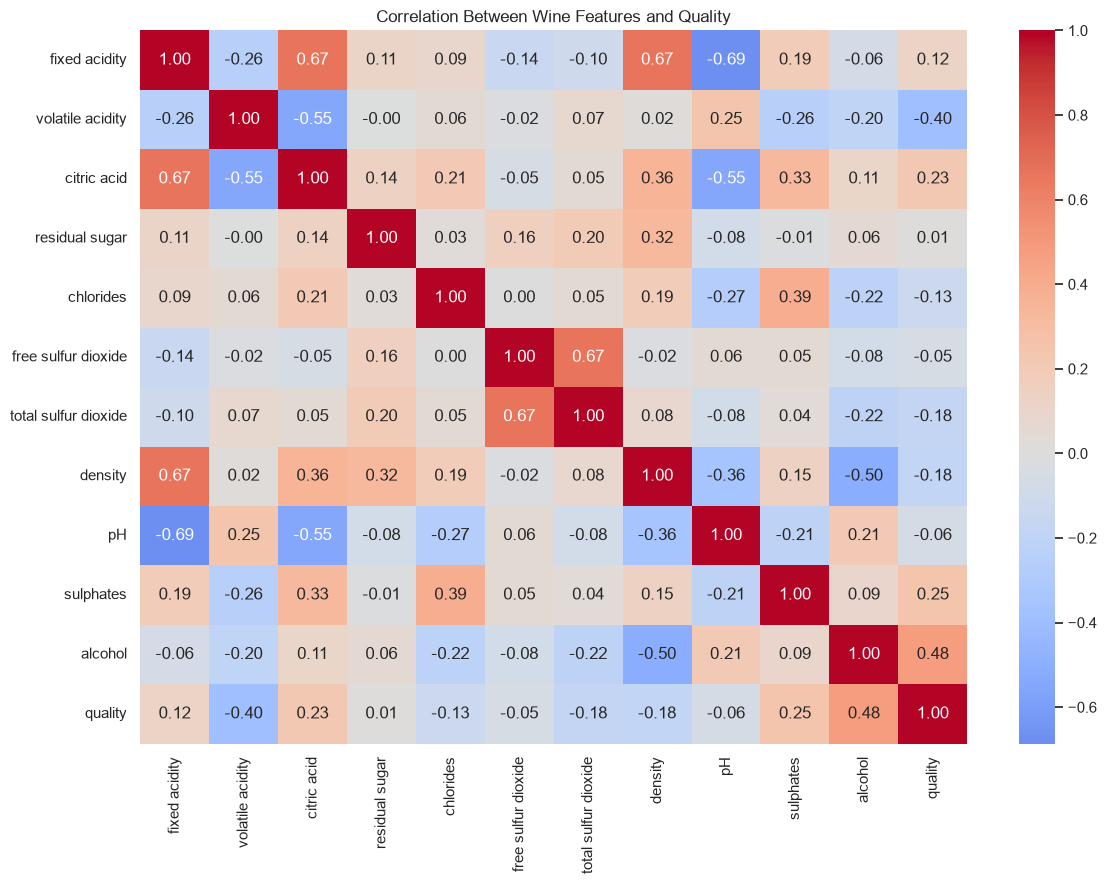

Features most positively correlated with quality:


,Correlation with quality
alcohol,0.480343
sulphates,0.248835
citric acid,0.228057
fixed acidity,0.119024
residual sugar,0.013640
free sulfur dioxide,-0.050463
pH,-0.055245
chlorides,-0.130988
total sulfur dioxide,-0.177855
density,-0.184252


In [8]:

correlation_matrix = df.corr(numeric_only=True)

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Between Wine Features and Quality")
plt.tight_layout()

plt.savefig(IMAGES_DIR / "correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

print("Features most positively correlated with quality:")
display(
    correlation_matrix["quality"]
    .drop("quality")
    .sort_values(ascending=False)
    .to_frame("Correlation with quality")
)


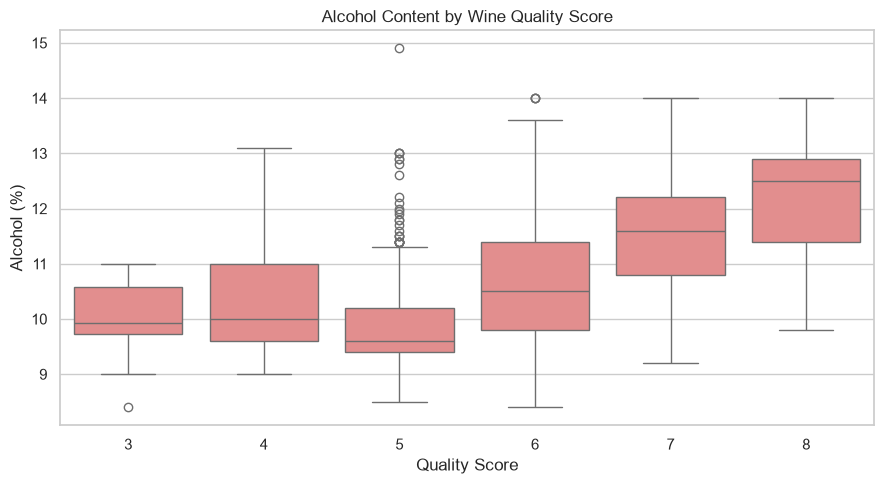

In [9]:

plt.figure(figsize=(9, 5))

sns.boxplot(data=df, x="quality", y="alcohol", color="lightcoral")

plt.title("Alcohol Content by Wine Quality Score")
plt.xlabel("Quality Score")
plt.ylabel("Alcohol (%)")
plt.tight_layout()

plt.savefig(IMAGES_DIR / "alcohol_by_quality.png", dpi=300, bbox_inches="tight")
plt.show()


In [10]:

X = df.drop(columns=["quality"])
y = df["quality"]

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nInput features:")
print(X.columns.tolist())

print("\nTarget summary:")
display(y.describe())


Feature matrix shape: (1359, 11)
Target shape: (1359,)

Input features:
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol']

Target summary:


count    1359.000000
mean        5.623252
std         0.823578
min         3.000000
25%         5.000000
50%         6.000000
75%         6.000000
max         8.000000
Name: quality, dtype: float64

In [11]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 1087
Testing samples: 272


In [12]:

linear_model = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

linear_model.fit(X_train, y_train)

linear_predictions = linear_model.predict(X_test)

print("Linear Regression training complete.")
print("First 10 predictions:")
print(np.round(linear_predictions[:10], 2))


Linear Regression training complete.
First 10 predictions:
[5.25 5.81 6.37 5.16 5.2  6.78 5.71 4.84 5.8  5.74]


Evaluate Linear Regression
I will measure performance using:
- MAE: average absolute prediction error.
- RMSE: prediction error with larger errors penalized more heavily.
- R²: how much variation in the target is explained by the model, relative to a mean-prediction baseline.

In [13]:

def evaluate_regression(model_name, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    return {
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    }

linear_results = evaluate_regression(
    "Linear Regression",
    y_test,
    linear_predictions
)

display(pd.DataFrame([linear_results]).round(4))


,Model,MAE,RMSE,R2
0,Linear Regression,0.5041,0.6565,0.3915


In [14]:

random_forest_model = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestRegressor(
        n_estimators=300,
        random_state=42,
        min_samples_leaf=2,
        n_jobs=-1
    ))
])

random_forest_model.fit(X_train, y_train)

rf_predictions = random_forest_model.predict(X_test)

print("Random Forest training complete.")
print("First 10 predictions:")
print(np.round(rf_predictions[:10], 2))


Random Forest training complete.
First 10 predictions:
[5.   5.92 6.4  5.36 5.4  6.79 5.55 5.1  5.9  5.55]


In [15]:

results = pd.DataFrame([
    evaluate_regression("Linear Regression", y_test, linear_predictions),
    evaluate_regression("Random Forest", y_test, rf_predictions)
])

results = results.sort_values("RMSE").reset_index(drop=True)

display(results.round(4))

best_model_name = results.loc[0, "Model"]
print("Model with the lowest test RMSE:", best_model_name)


,Model,MAE,RMSE,R2
0,Random Forest,0.4654,0.6171,0.4625
1,Linear Regression,0.5041,0.6565,0.3915


Model with the lowest test RMSE: Random Forest


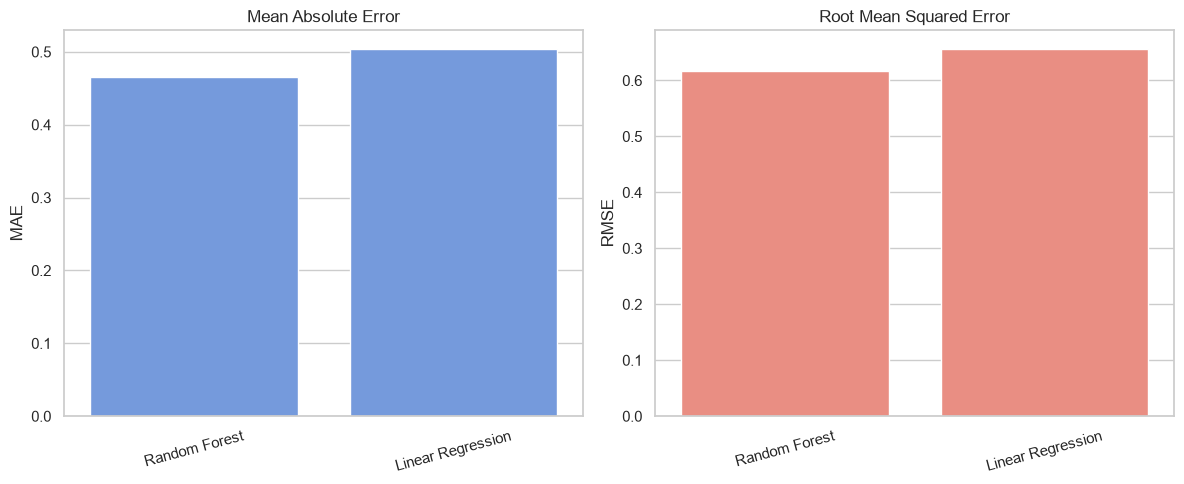

In [16]:

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.barplot(data=results, x="Model", y="MAE", ax=axes[0], color="cornflowerblue")
axes[0].set_title("Mean Absolute Error")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=15)

sns.barplot(data=results, x="Model", y="RMSE", ax=axes[1], color="salmon")
axes[1].set_title("Root Mean Squared Error")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.savefig(IMAGES_DIR / "model_comparison.png", dpi=300, bbox_inches="tight")
plt.show()


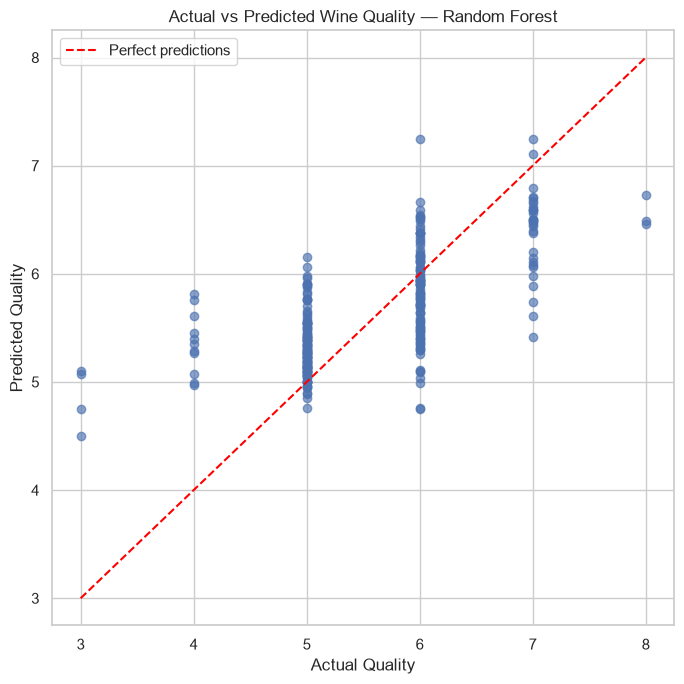

In [17]:

prediction_map = {
    "Linear Regression": linear_predictions,
    "Random Forest": rf_predictions
}

best_predictions = prediction_map[best_model_name]

plt.figure(figsize=(7, 7))

plt.scatter(y_test, best_predictions, alpha=0.65)

minimum = min(y_test.min(), best_predictions.min())
maximum = max(y_test.max(), best_predictions.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--",
    color="red",
    label="Perfect predictions"
)

plt.xlabel("Actual Quality")
plt.ylabel("Predicted Quality")
plt.title(f"Actual vs Predicted Wine Quality — {best_model_name}")
plt.legend()
plt.tight_layout()

plt.savefig(IMAGES_DIR / "actual_vs_predicted.png", dpi=300, bbox_inches="tight")
plt.show()


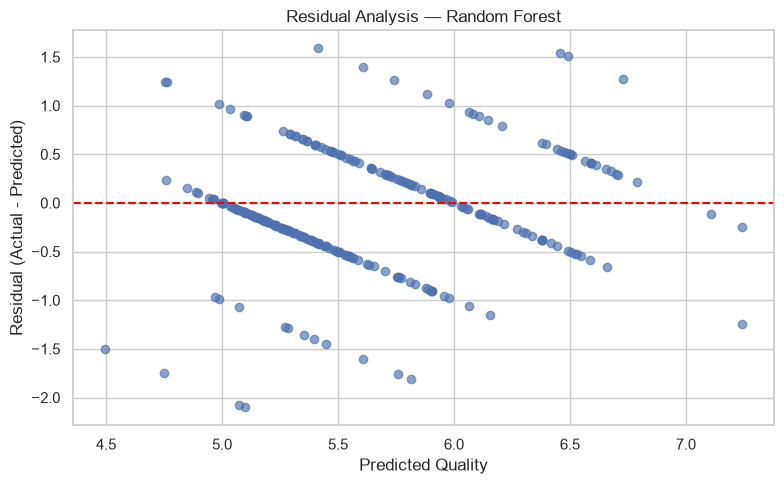

Mean residual: -0.0812
Residual standard deviation: 0.6117


In [18]:

residuals = y_test.to_numpy() - best_predictions

plt.figure(figsize=(8, 5))

plt.scatter(best_predictions, residuals, alpha=0.65)
plt.axhline(0, color="red", linestyle="--")

plt.xlabel("Predicted Quality")
plt.ylabel("Residual (Actual - Predicted)")
plt.title(f"Residual Analysis — {best_model_name}")
plt.tight_layout()

plt.savefig(IMAGES_DIR / "residual_analysis.png", dpi=300, bbox_inches="tight")
plt.show()

print("Mean residual:", round(float(np.mean(residuals)), 4))
print("Residual standard deviation:", round(float(np.std(residuals)), 4))


,Feature,Importance
10,alcohol,0.2911
9,sulphates,0.1381
1,volatile acidity,0.1172
6,total sulfur dioxide,0.0783
4,chlorides,0.0659
8,pH,0.0557
3,residual sugar,0.0533
7,density,0.0529
0,fixed acidity,0.0507
5,free sulfur dioxide,0.0494


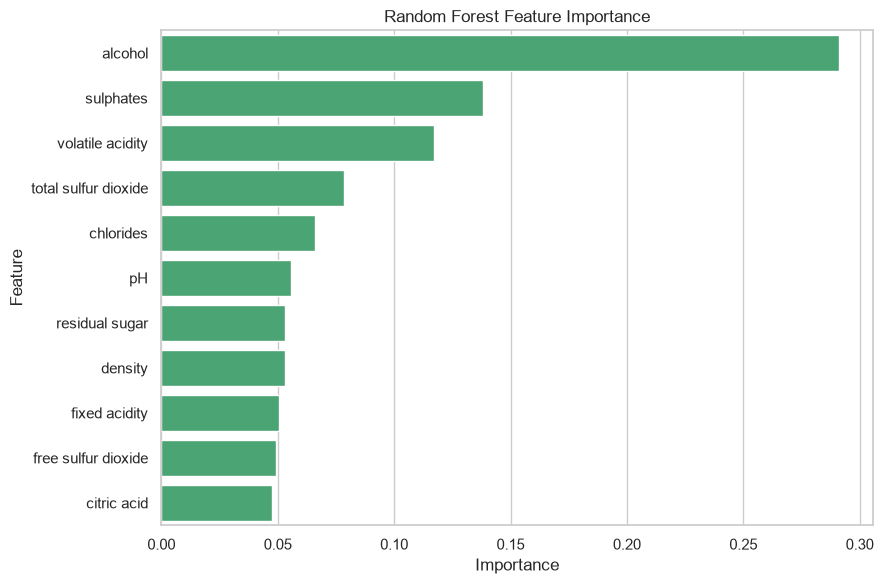

In [19]:

rf_estimator = random_forest_model.named_steps["model"]

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_estimator.feature_importances_
}).sort_values("Importance", ascending=False)

display(feature_importance.round(4))

plt.figure(figsize=(9, 6))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature",
    color="mediumseagreen"
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()

plt.savefig(IMAGES_DIR / "feature_importance.png", dpi=300, bbox_inches="tight")
plt.show()


In [20]:

sample = X_test.iloc[[0]]

actual_quality = y_test.iloc[0]
predicted_quality = best_predictions[0]

print("Sample wine measurements:")
display(sample)

print("Actual quality:", actual_quality)
print("Predicted quality:", round(float(predicted_quality), 2))
print("Absolute prediction error:", round(abs(actual_quality - predicted_quality), 2))


Sample wine measurements:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
55,7.7,0.62,0.04,3.8,0.084,25.0,45.0,0.9978,3.34,0.53,9.5


Actual quality: 5
Predicted quality: 5.0
Absolute prediction error: 0.0


In [21]:

prediction_results = pd.DataFrame({
    "Actual_Quality": y_test.to_numpy(),
    "Linear_Regression_Prediction": linear_predictions,
    "Random_Forest_Prediction": rf_predictions
})

prediction_results["Best_Model_Prediction"] = best_predictions
prediction_results["Best_Model"] = best_model_name

prediction_results.to_csv(
    PROJECT_DIR / "test_predictions.csv",
    index=False
)

results.to_csv(
    PROJECT_DIR / "model_evaluation.csv",
    index=False
)

print("Saved test_predictions.csv")
print("Saved model_evaluation.csv")


Saved test_predictions.csv
Saved model_evaluation.csv


In [22]:

print("=" * 55)
print("WINE QUALITY PREDICTION — FINAL SUMMARY")
print("=" * 55)

print("\nDataset")
print("Number of cleaned samples:", len(df))
print("Number of input features:", X.shape[1])
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nModel comparison")
display(results.round(4))

print("\nSelected model:", best_model_name)

print("\nTop 5 Random Forest features")
display(feature_importance.head(5).round(4))

print("\nInterpretation")
print(
    f"The model selected by test RMSE was {best_model_name}. "
    f"Its test RMSE was "
    f"{results.loc[results['Model'] == best_model_name, 'RMSE'].iloc[0]:.4f}."
)
print(
    "Review the visualizations and model metrics before making conclusions "
    "about which features relate to wine quality."
)


WINE QUALITY PREDICTION — FINAL SUMMARY

Dataset
Number of cleaned samples: 1359
Number of input features: 11
Training samples: 1087
Testing samples: 272

Model comparison


,Model,MAE,RMSE,R2
0,Random Forest,0.4654,0.6171,0.4625
1,Linear Regression,0.5041,0.6565,0.3915



Selected model: Random Forest

Top 5 Random Forest features


,Feature,Importance
10,alcohol,0.2911
9,sulphates,0.1381
1,volatile acidity,0.1172
6,total sulfur dioxide,0.0783
4,chlorides,0.0659



Interpretation
The model selected by test RMSE was Random Forest. Its test RMSE was 0.6171.
Review the visualizations and model metrics before making conclusions about which features relate to wine quality.


## Conclusion

This project analyzed the UCI Red Wine Quality dataset to explore the relationship between physicochemical properties and wine quality and to predict quality scores using machine learning.

After data cleaning, the dataset contained **1,359 samples and 11 input features**. Exploratory Data Analysis was performed using quality-score distributions, feature histograms, a correlation heatmap, and a comparison of alcohol content across quality scores.

Two regression models were trained and evaluated: Linear Regression and Random Forest Regression. Their performance was compared using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R-squared (R²).

**Random Forest performed better than Linear Regression on the test set.** Random Forest achieved an MAE of **0.4654**, an RMSE of **0.6171**, and an R² of **0.4625**. In comparison, Linear Regression achieved an MAE of **0.5041**, an RMSE of **0.6565**, and an R² of **0.3915**. These results indicate that Random Forest produced smaller prediction errors and explained a larger proportion of the variation in quality scores on this test set.

The Random Forest feature-importance analysis identified **alcohol (0.2911)** as the most important feature, followed by **sulphates (0.1381)**, **volatile acidity (0.1172)**, **total sulfur dioxide (0.0783)**, and **chlorides (0.0659)**. These values describe how the fitted model used the features; they do not prove that these properties directly cause changes in wine quality.

Overall, this project demonstrates how exploratory data analysis and regression models can be used to estimate wine quality from physicochemical measurements. However, the R² score of 0.4625 indicates that substantial variation remains unexplained. The predictions should therefore be treated as estimates rather than exact quality ratings. Further improvements could include hyperparameter tuning, cross-validation, and testing additional models.